<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter7/jumping_pendulum_real_trajectories.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Jumping Pendulum Spatial Trajectories.

<>:77: SyntaxWarning: invalid escape sequence '\g'
<>:78: SyntaxWarning: invalid escape sequence '\g'
<>:79: SyntaxWarning: invalid escape sequence '\g'
<>:80: SyntaxWarning: invalid escape sequence '\g'
<>:77: SyntaxWarning: invalid escape sequence '\g'
<>:78: SyntaxWarning: invalid escape sequence '\g'
<>:79: SyntaxWarning: invalid escape sequence '\g'
<>:80: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_1149/498965985.py:77: SyntaxWarning: invalid escape sequence '\g'
  {"title": "(a) Inelastic String (Baseline)\n$e=0, \gamma=1$ ($u_0 = 0.819$)", "e": 0.0, "gamma": 1.0, "u0": 0.819},
/tmp/ipykernel_1149/498965985.py:78: SyntaxWarning: invalid escape sequence '\g'
  {"title": "(b) Elastic String\n$e=0.8, \gamma=1$ ($u_0 = 0.819$)", "e": 0.8, "gamma": 1.0, "u0": 0.819},
/tmp/ipykernel_1149/498965985.py:79: SyntaxWarning: invalid escape sequence '\g'
  {"title": "(c) Heavy Pivot Friction (Hard Stop)\n$e=0, \gamma=0.7$ ($u_0 = 0.819$)", "e": 0.0, "gamma": 0.7, "u0": 0.819},

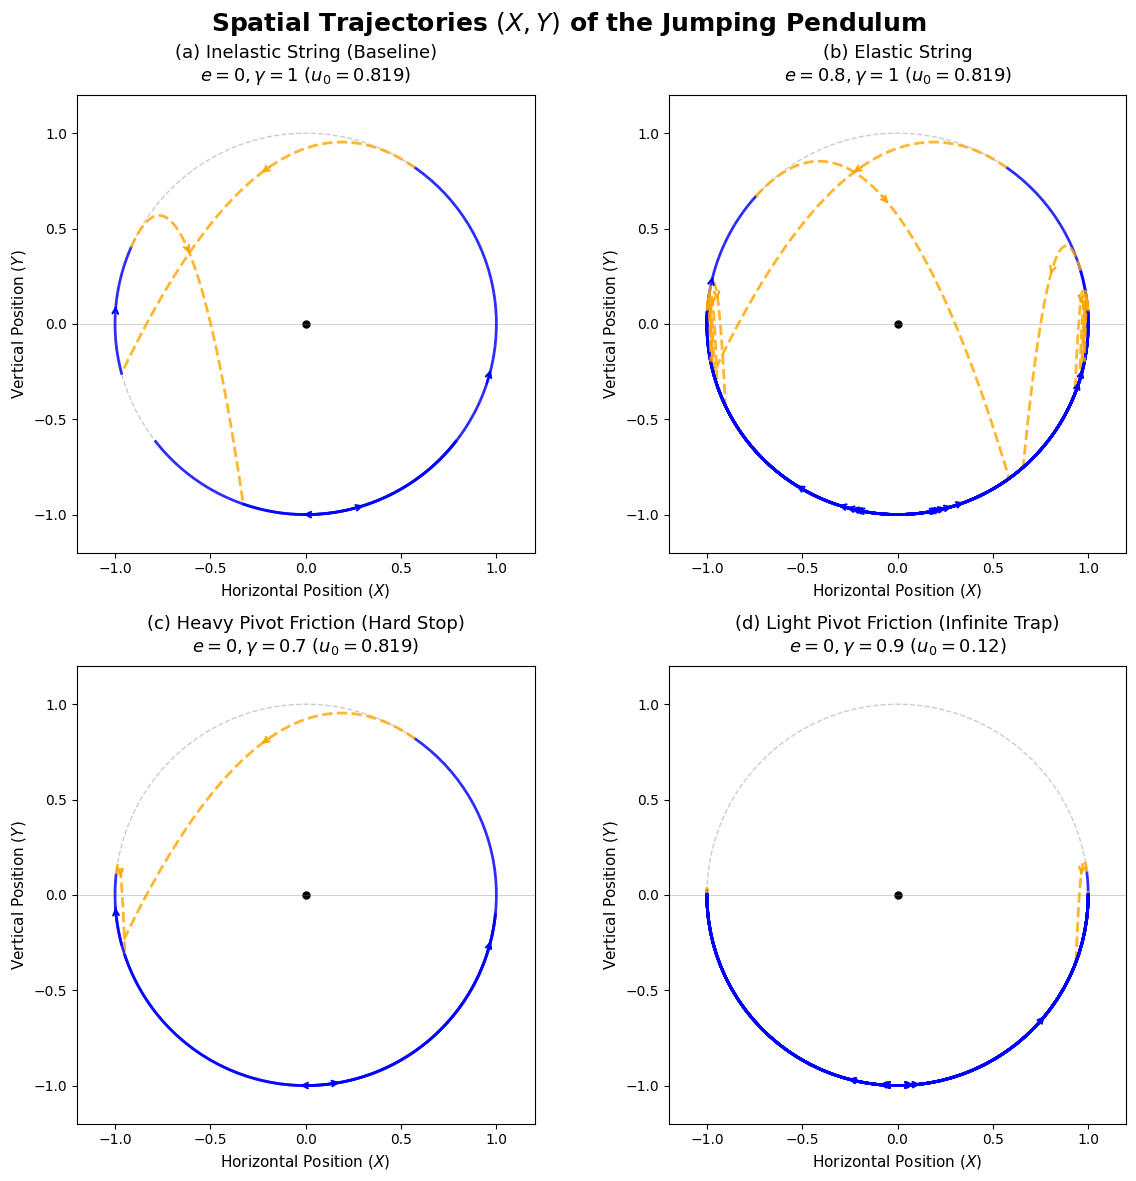

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def normalize(th):
    """Normalize angles to the [-pi, pi] domain."""
    return (th + np.pi) % (2 * np.pi) - np.pi

def calculate_impact(u, e, gamma):
    """Calculates the new energy state after the landing shock."""
    loss_n = (64/3) * (u**3) * (1 - u**2)**3
    loss_t = 3*u - (8/3)*(u**3) - loss_n
    return u - (1 - e**2) * loss_n - (1 - gamma**2) * loss_t

def get_spatial_trajectory(u0, e=0.0, gamma=1.0, max_jumps=15):
    """
    Generates the physical (x, y) coordinates for the pendulum.
    Returns a list of plotting segments for arcs and parabolas.
    """
    segments = []

    current_u = u0
    current_E = 1.5 * current_u
    om_sign = 1  # Start by swinging right
    start_th = 0.0

    for n in range(max_jumps):
        if current_u <= 0:
            # PURE OSCILLATION PHASE
            current_E = max(current_E, -1.0)
            th_max = om_sign * np.arccos(-current_E)

            # Swing to the turning point
            th_vals = np.linspace(start_th, th_max, 50)
            segments.append({'x': np.sin(th_vals), 'y': -np.cos(th_vals), 'style': '-', 'color': 'blue'})

            # Swing back one full arc
            th_vals_back = np.linspace(th_max, -th_max, 100)
            segments.append({'x': np.sin(th_vals_back), 'y': -np.cos(th_vals_back), 'style': '-', 'color': 'blue'})
            break

        # JUMPING PHASE
        # 1. Taut swing up to the take-off point
        th_takeoff = om_sign * np.arccos(-current_u)
        th_vals = np.linspace(start_th, th_takeoff, 50)
        segments.append({'x': np.sin(th_vals), 'y': -np.cos(th_vals), 'style': '-', 'color': 'blue'})

        # 2. Parabolic Free-Fall
        # Calculate takeoff velocity components
        omega_1 = om_sign * np.sqrt(current_u)
        vx = omega_1 * np.cos(th_takeoff)
        vy = omega_1 * np.sin(th_takeoff)

        # Flight time (g=1, L=1)
        tf = 4 * abs(omega_1 * np.sin(th_takeoff))

        t_vals = np.linspace(0, tf, 50)
        x_vals = np.sin(th_takeoff) + vx * t_vals
        y_vals = -np.cos(th_takeoff) + vy * t_vals - 0.5 * t_vals**2

        segments.append({'x': x_vals, 'y': y_vals, 'style': '--', 'color': 'orange', 'label': 'Free Fall'})

        # 3. The Landing Shock
        next_u = calculate_impact(current_u, e, gamma)

        current_u = next_u
        current_E = 1.5 * next_u
        start_th = normalize(-3 * th_takeoff)
        om_sign = -om_sign

    return segments

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.flatten()
plt.suptitle("Spatial Trajectories $(X, Y)$ of the Jumping Pendulum", fontsize=18, fontweight='bold')

models = [
    {"title": "(a) Inelastic String (Baseline)\n$e=0, \gamma=1$ ($u_0 = 0.819$)", "e": 0.0, "gamma": 1.0, "u0": 0.819},
    {"title": "(b) Elastic String\n$e=0.8, \gamma=1$ ($u_0 = 0.819$)", "e": 0.8, "gamma": 1.0, "u0": 0.819},
    {"title": "(c) Heavy Pivot Friction (Hard Stop)\n$e=0, \gamma=0.7$ ($u_0 = 0.819$)", "e": 0.0, "gamma": 0.7, "u0": 0.819},
    {"title": "(d) Light Pivot Friction (Infinite Trap)\n$e=0, \gamma=0.9$ ($u_0 = 0.12$)", "e": 0.0, "gamma": 0.9, "u0": 0.12}
]

for ax, model in zip(axes, models):
    # Draw the boundary circle and pivot
    circle = plt.Circle((0, 0), 1, color='gray', fill=False, linestyle='--', alpha=0.4)
    ax.add_patch(circle)
    ax.plot(0, 0, 'ko', markersize=5)
    ax.axhline(0, color='gray', linestyle='-', linewidth=0.5, alpha=0.5)

    # Generate and Plot the Trajectory
    segments = get_spatial_trajectory(model['u0'], e=model['e'], gamma=model['gamma'])

    added_labels = set()
    for seg in segments:
        label = seg.get('label', None)
        if label and label in added_labels:
            label = None
        elif label:
            added_labels.add(label)

        ax.plot(seg['x'], seg['y'], linestyle=seg['style'], color=seg['color'],
                linewidth=2, alpha=0.8, label=label)

        # Add directional arrows for visualization
        x_vals, y_vals = seg['x'], seg['y']

        # Calculate the total physical distance of this segment
        dist = np.hypot(x_vals[-1] - x_vals[0], y_vals[-1] - y_vals[0])

        # Only draw arrows on longer segments to prevent massive visual clutter in the traps
        if dist > 0.3 and len(x_vals) >= 3:
            mid_idx = len(x_vals) // 2
            # Use two adjacent points near the middle to give the arrowhead its direction vector
            ax.annotate('', xy=(x_vals[mid_idx+1], y_vals[mid_idx+1]),
                        xytext=(x_vals[mid_idx-1], y_vals[mid_idx-1]),
                        arrowprops=dict(arrowstyle="->", color=seg['color'], lw=1.5))

    # Formatting
    ax.set_title(model['title'], fontsize=13, pad=10)
    ax.set_aspect('equal')
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_xlabel('Horizontal Position ($X$)', fontsize=11)
    ax.set_ylabel('Vertical Position ($Y$)', fontsize=11)

plt.tight_layout()
plt.show()